# TEXT CLASSIFICATION BATTLE
### Compare, Analyze and Defend: A Machine Learning Text Classification Study

**Course:** Information Retrieval  
**Institution:** SRM Institute of Science and Technology  
**Project Type:** Comparative Machine Learning Analysis

---

 Project Overview

This project explores text classification using the BBC News dataset. The objective is to classify news articles into five categories—**Business, Entertainment, Politics, Sport, and Tech**—and compare the performance of four machine learning classifiers.

 Objectives

- Load and explore the BBC News dataset.
- Preprocess the text data for machine learning.
- Convert text into numerical features using **TF-IDF vectorization**.
- Train and evaluate four classification algorithms.
- Compare model performance using accuracy, precision, recall, and F1-score.
- Visualize model performance using confusion matrices and comparison graphs.
- Conduct a what-if experiment to investigate the effect of changing the K-Nearest Neighbors (KNN) parameter.
- Analyze the results and defend the selection of the best-performing model.

 Machine Learning Models

1. Decision Tree Classifier
2. K-Nearest Neighbors (KNN)
3. Support Vector Machine (SVM)
4. Multinomial Naive Bayes

Evaluation Approach

The dataset is divided into training and testing sets using an 80:20 split. The text is transformed into TF-IDF features, and all four classifiers are evaluated on the test set using standard classification metrics.

Expected Outcome

The experiment aims to identify which classifier performs best on this dataset, explain the differences in model performance, and justify the final model selection using quantitative evaluation results.

---

**Note:** All experiments, evaluation metrics, visualizations, and conclusions are documented in the notebook cells below.

In [1]:

from google.colab import files

uploaded = files.upload()


Saving BBC News Train.csv to BBC News Train.csv


In [2]:
import pandas as pd
from IPython.display import display

# Load the uploaded dataset
df = pd.read_csv(next(iter(uploaded)))

# Display dataset information
print("Dataset loaded successfully!")
print("-" * 40)

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five articles:")
display(df.head())

print("\nMissing values:")
print(df.isnull().sum())

Dataset loaded successfully!
----------------------------------------
Dataset shape: (1490, 3)

Column names:
['ArticleId', 'Text', 'Category']

First five articles:


,ArticleId,Text,Category
0,1833,worldcom ex-boss launches defence lawyers defe...,business
1,154,german business confidence slides german busin...,business
2,1101,bbc poll indicates economic gloom citizens in ...,business
3,1976,lifestyle governs mobile choice faster bett...,tech
4,917,enron bosses in $168m payout eighteen former e...,business



Missing values:
ArticleId    0
Text         0
Category     0
dtype: int64


In [3]:
print("TOTAL NUMBER OF ARTICLES:", len(df))

print("\nNUMBER OF UNIQUE CATEGORIES:",
      df["Category"].nunique())

print("\nCATEGORY LABELS:")
print(df["Category"].unique())

print("\nARTICLES PER CATEGORY:")
category_counts = df["Category"].value_counts()

print(category_counts)

TOTAL NUMBER OF ARTICLES: 1490

NUMBER OF UNIQUE CATEGORIES: 5

CATEGORY LABELS:
['business' 'tech' 'politics' 'sport' 'entertainment']

ARTICLES PER CATEGORY:
Category
sport            346
business         336
politics         274
entertainment    273
tech             261
Name: count, dtype: int64


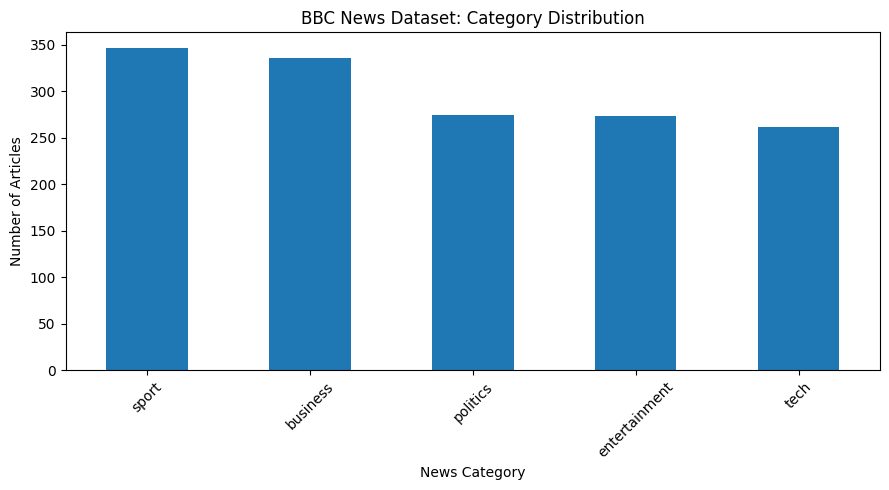

In [4]:
import matplotlib.pyplot as plt

# Count articles in each category
category_counts = df["Category"].value_counts()

# Create bar chart
plt.figure(figsize=(9, 5))

category_counts.plot(kind="bar")

plt.title("BBC News Dataset: Category Distribution")
plt.xlabel("News Category")
plt.ylabel("Number of Articles")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [5]:
# ==========================================
# CLASS IMBALANCE ANALYSIS
# ==========================================

category_percentages = (
    df["Category"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("CATEGORY DISTRIBUTION (%):")
print(category_percentages)

print("\nLargest class size:",
      df["Category"].value_counts().max())

print("Smallest class size:",
      df["Category"].value_counts().min())

CATEGORY DISTRIBUTION (%):
Category
sport            23.22
business         22.55
politics         18.39
entertainment    18.32
tech             17.52
Name: proportion, dtype: float64

Largest class size: 346
Smallest class size: 261


In [6]:
# ==========================================
# CLASS IMBALANCE ANALYSIS
# ==========================================

category_percentages = (
    df["Category"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("CATEGORY DISTRIBUTION (%):")
print(category_percentages)

print("\nLargest class size:",
      df["Category"].value_counts().max())

print("Smallest class size:",
      df["Category"].value_counts().min())

CATEGORY DISTRIBUTION (%):
Category
sport            23.22
business         22.55
politics         18.39
entertainment    18.32
tech             17.52
Name: proportion, dtype: float64

Largest class size: 346
Smallest class size: 261


In [7]:
# Prepare the input text and target labels

df = df.dropna(subset=["Text", "Category"]).copy()

# Remove empty text rows
df = df[df["Text"].str.strip() != ""].copy()

# Input features and target labels
X = df["Text"]
y = df["Category"]

print("Dataset variables created successfully!")
print("Total articles:", len(X))
print("Total labels:", len(y))
print("Categories:", sorted(y.unique()))

Dataset variables created successfully!
Total articles: 1490
Total labels: 1490
Categories: ['business', 'entertainment', 'politics', 'sport', 'tech']


In [8]:
from sklearn.model_selection import train_test_split

X_train_text, X_test_text, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training articles:", len(X_train_text))
print("Testing articles:", len(X_test_text))

print("\nTraining category distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting category distribution:")
print(y_test.value_counts().sort_index())

Training articles: 1192
Testing articles: 298

Training category distribution:
Category
business         269
entertainment    218
politics         219
sport            277
tech             209
Name: count, dtype: int64

Testing category distribution:
Category
business         67
entertainment    55
politics         55
sport            69
tech             52
Name: count, dtype: int64


In [9]:
# ==========================================
# PHASE 3: TF-IDF FEATURE EXTRACTION
# ==========================================

from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize TF-IDF vectorizer
tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    max_features=5000,
    ngram_range=(1, 1),
    min_df=2
)

# Learn vocabulary from training data only
X_train = tfidf.fit_transform(X_train_text)

# Transform test data using the same vocabulary
X_test = tfidf.transform(X_test_text)

print("TF-IDF conversion completed successfully!")

print("\nTraining matrix shape:", X_train.shape)
print("Testing matrix shape:", X_test.shape)
print("Vocabulary size:", len(tfidf.vocabulary_))
print("Training labels:", len(y_train))
print("Testing labels:", len(y_test))

TF-IDF conversion completed successfully!

Training matrix shape: (1192, 5000)
Testing matrix shape: (298, 5000)
Vocabulary size: 5000
Training labels: 1192
Testing labels: 298


In [10]:

# ==========================================
# PHASE 4: MODEL INITIALIZATION
# ==========================================

from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB

# Define all four classifiers
models = {
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5,
        metric="cosine",
        algorithm="brute"
    ),

    "SVM": LinearSVC(
        random_state=42,
        max_iter=5000
    ),

    "Naive Bayes": MultinomialNB(
        alpha=1.0
    )
}

print("All four classifiers initialized successfully!")

for name, model in models.items():
    print(f"{name}: {model.__class__.__name__}")


All four classifiers initialized successfully!
Decision Tree: DecisionTreeClassifier
KNN: KNeighborsClassifier
SVM: LinearSVC
Naive Bayes: MultinomialNB


In [11]:
# ==========================================
# PHASE 4: MODEL TRAINING AND EVALUATION
# ==========================================

import time
import pandas as pd
from IPython.display import display

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

results = []
predictions = {}

for name, model in models.items():

    print(f"\nTraining {name}...")

    # Measure training time
    start_train = time.perf_counter()
    model.fit(X_train, y_train)
    training_time = time.perf_counter() - start_train

    # Measure prediction time
    start_test = time.perf_counter()
    y_pred = model.predict(X_test)
    testing_time = time.perf_counter() - start_test

    predictions[name] = y_pred

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_test, y_pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred,
        average="macro",
        zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision (Macro)": precision,
        "Recall (Macro)": recall,
        "F1-score (Macro)": f1,
        "Training Time (s)": training_time,
        "Testing Time (s)": testing_time
    })

    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1-score: {f1:.4f}")
    print(f"Training time: {training_time:.4f} seconds")
    print(f"Testing time: {testing_time:.4f} seconds")

# Create the comparison table
results_df = pd.DataFrame(results)

print("\n========== FINAL COMPARISON TABLE ==========")

display(
    results_df.sort_values(
        by="F1-score (Macro)",
        ascending=False
    )
)


Training Decision Tree...
Accuracy: 0.8289
Precision: 0.8272
Recall: 0.8221
F1-score: 0.8240
Training time: 1.8840 seconds
Testing time: 0.0033 seconds

Training KNN...
Accuracy: 0.9228
Precision: 0.9195
Recall: 0.9195
F1-score: 0.9193
Training time: 0.0093 seconds
Testing time: 0.1111 seconds

Training SVM...
Accuracy: 0.9765
Precision: 0.9764
Recall: 0.9750
F1-score: 0.9755
Training time: 0.1640 seconds
Testing time: 0.0052 seconds

Training Naive Bayes...
Accuracy: 0.9765
Precision: 0.9761
Recall: 0.9754
F1-score: 0.9757
Training time: 0.0203 seconds
Testing time: 0.0009 seconds

========== FINAL COMPARISON TABLE ==========


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro),Training Time (s),Testing Time (s)
3,Naive Bayes,0.976510,0.976077,0.975428,0.975726,0.020306,0.000868
2,SVM,0.976510,0.976437,0.975009,0.975482,0.163977,0.005245
1,KNN,0.922819,0.919471,0.919454,0.919314,0.009304,0.111080
0,Decision Tree,0.828859,0.827217,0.822143,0.823992,1.884040,0.003330



Confusion Matrix: Decision Tree
[[56  3  2  1  5]
 [ 2 41  3  4  5]
 [ 7  1 45  1  1]
 [ 2  1  0 65  1]
 [ 5  7  0  0 40]]


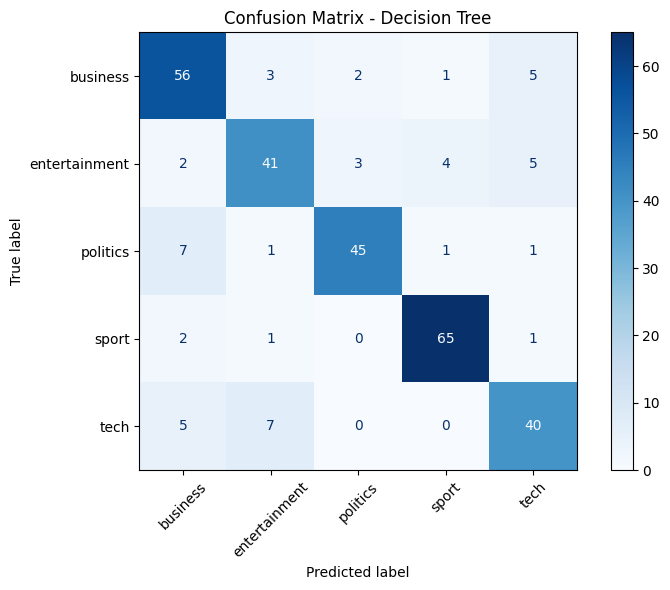


Confusion Matrix: KNN
[[60  0  6  1  0]
 [ 0 53  0  0  2]
 [ 4  0 48  0  3]
 [ 0  0  0 69  0]
 [ 2  4  1  0 45]]


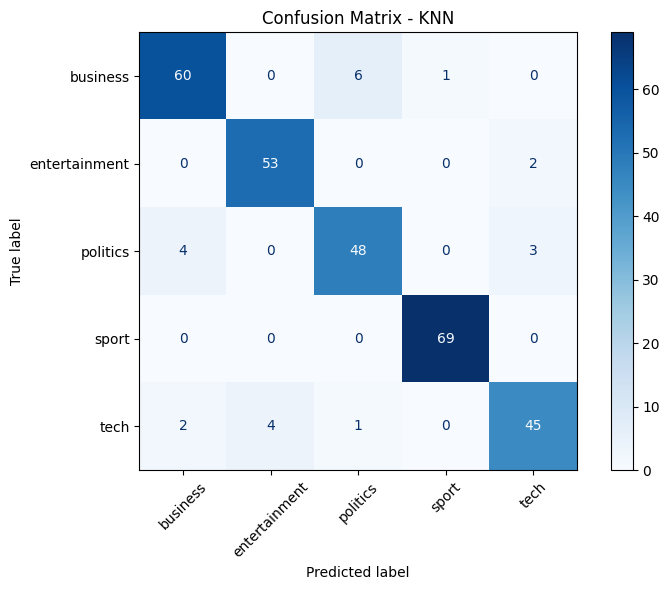


Confusion Matrix: SVM
[[65  0  1  1  0]
 [ 0 55  0  0  0]
 [ 0  0 54  0  1]
 [ 0  0  0 69  0]
 [ 2  2  0  0 48]]


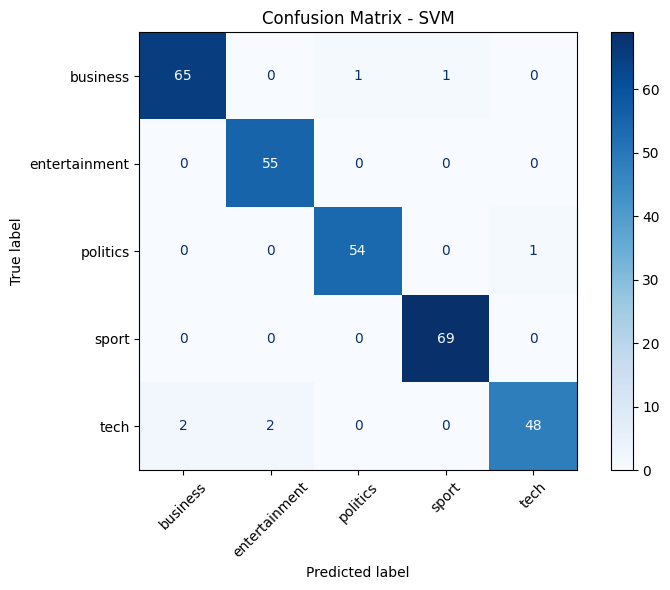


Confusion Matrix: Naive Bayes
[[65  0  2  0  0]
 [ 0 55  0  0  0]
 [ 1  0 52  0  2]
 [ 0  0  0 69  0]
 [ 2  0  0  0 50]]


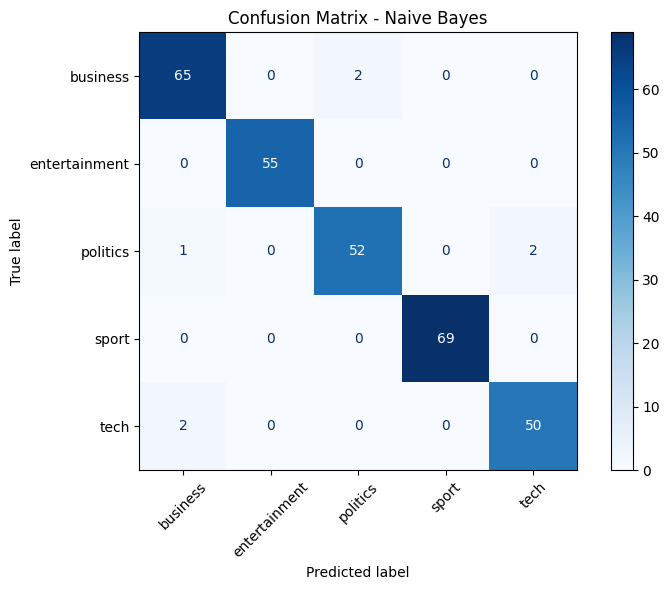

In [12]:
# ==========================================
# PHASE 5: CONFUSION MATRIX ANALYSIS
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Ensure y_test exists in namespace before running
if 'y_test' in globals():
    # Use the actual category labels
    class_names = sorted(y_test.unique())

    for name, y_pred in predictions.items():
        cm = confusion_matrix(
            y_test,
            y_pred,
            labels=class_names
        )

        print(f"\nConfusion Matrix: {name}")
        print(cm)

        display_matrix = ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=class_names
        )

        fig, ax = plt.subplots(figsize=(8, 6))
        display_matrix.plot(
            ax=ax,
            cmap="Blues",
            xticks_rotation=45,
            values_format="d"
        )

        plt.title(f"Confusion Matrix - {name}")
        plt.tight_layout()
        plt.show()
else:
    print("Error: 'y_test' is still not defined. Please run the train_test_split cell (Phase 3) first.")

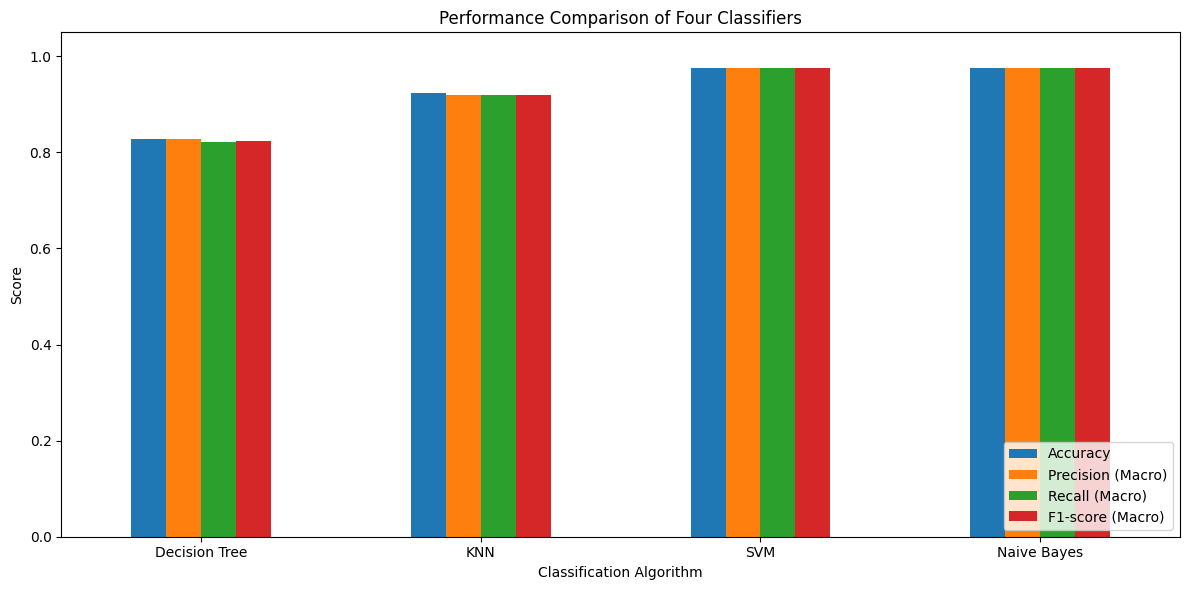

In [13]:
# ==========================================
# MODEL PERFORMANCE COMPARISON
# ==========================================

import matplotlib.pyplot as plt

metrics = [
    "Accuracy",
    "Precision (Macro)",
    "Recall (Macro)",
    "F1-score (Macro)"
]

plot_data = results_df.set_index("Model")[metrics]

ax = plot_data.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Performance Comparison of Four Classifiers")
plt.ylabel("Score")
plt.xlabel("Classification Algorithm")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [14]:
# ==========================================
# PHASE 7: WHAT-IF EXPERIMENT
# Compare KNN with K=5 and K=9
# ==========================================

import time
import pandas as pd

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

knn_results = []

for k in [3, 5, 7, 9, 11]:

    print(f"\nEvaluating KNN with K={k}")

    model = KNeighborsClassifier(
        n_neighbors=k,
        metric="cosine",
        algorithm="brute"
    )

    start_train = time.perf_counter()
    model.fit(X_train, y_train)
    training_time = time.perf_counter() - start_train

    start_test = time.perf_counter()
    y_pred = model.predict(X_test)
    testing_time = time.perf_counter() - start_test

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    knn_results.append({
        "K": k,
        "Accuracy": accuracy,
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1-score": f1,
        "Training Time (s)": training_time,
        "Testing Time (s)": testing_time
    })

knn_comparison = pd.DataFrame(knn_results)

print("\nKNN WHAT-IF EXPERIMENT RESULTS:")
from IPython.display import display as show_table

show_table(knn_comparison)


Evaluating KNN with K=3

Evaluating KNN with K=5

Evaluating KNN with K=7

Evaluating KNN with K=9

Evaluating KNN with K=11

KNN WHAT-IF EXPERIMENT RESULTS:


,K,Accuracy,Macro Precision,Macro Recall,Macro F1-score,Training Time (s),Testing Time (s)
0,3,0.926174,0.923991,0.922859,0.923374,0.005467,0.081536
1,5,0.922819,0.919471,0.919454,0.919314,0.003445,0.095933
2,7,0.929530,0.927146,0.928008,0.927425,0.008457,0.116499
3,9,0.936242,0.933435,0.933768,0.933501,0.007575,0.137129
4,11,0.936242,0.933915,0.934629,0.934110,0.003540,0.069603


In [15]:
import pandas as pd
from IPython.display import display as show_table

# Convert the list of dictionaries into a DataFrame
results_df = pd.DataFrame(results)

# Display the final comparison table
print("FINAL COMPARISON OF FOUR CLASSIFIERS")
show_table(results_df.round(4))

# Find the best model based on Macro F1-score
best_model = results_df.loc[
    results_df["F1-score (Macro)"].idxmax()
]

print("\nBEST-PERFORMING CLASSIFIER")
print("Model:", best_model["Model"])
print("Accuracy:", round(best_model["Accuracy"] * 100, 2), "%")
print("Macro Precision:", round(best_model["Precision (Macro)"] * 100, 2), "%")
print("Macro Recall:", round(best_model["Recall (Macro)"] * 100, 2), "%")
print("Macro F1-score:", round(best_model["F1-score (Macro)"] * 100, 2), "%")

FINAL COMPARISON OF FOUR CLASSIFIERS


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro),Training Time (s),Testing Time (s)
0,Decision Tree,0.8289,0.8272,0.8221,0.8240,1.8840,0.0033
1,KNN,0.9228,0.9195,0.9195,0.9193,0.0093,0.1111
2,SVM,0.9765,0.9764,0.9750,0.9755,0.1640,0.0052
3,Naive Bayes,0.9765,0.9761,0.9754,0.9757,0.0203,0.0009



BEST-PERFORMING CLASSIFIER
Model: Naive Bayes
Accuracy: 97.65 %
Macro Precision: 97.61 %
Macro Recall: 97.54 %
Macro F1-score: 97.57 %


In [16]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd
from IPython.display import display as show_table
import time

# Experiment with different K values
k_values = [3, 5, 7, 9, 11]
knn_results = []

for k in k_values:
    print(f"Evaluating KNN with K={k}")

    model = KNeighborsClassifier(
        n_neighbors=k,
        metric="cosine",
        algorithm="brute"
    )

    start_train = time.perf_counter()
    model.fit(X_train, y_train)
    train_time = time.perf_counter() - start_train

    start_test = time.perf_counter()
    predictions = model.predict(X_test)
    test_time = time.perf_counter() - start_test

    knn_results.append({
        "K Value": k,
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro Precision": precision_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Macro F1-score": f1_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Training Time (s)": train_time,
        "Testing Time (s)": test_time
    })

knn_comparison = pd.DataFrame(knn_results)

print("KNN WHAT-IF EXPERIMENT RESULTS")
show_table(knn_comparison.round(4))

Evaluating KNN with K=3
Evaluating KNN with K=5
Evaluating KNN with K=7
Evaluating KNN with K=9
Evaluating KNN with K=11
KNN WHAT-IF EXPERIMENT RESULTS


,K Value,Accuracy,Macro Precision,Macro Recall,Macro F1-score,Training Time (s),Testing Time (s)
0,3,0.9262,0.9240,0.9229,0.9234,0.0153,0.0654
1,5,0.9228,0.9195,0.9195,0.9193,0.0045,0.1397
2,7,0.9295,0.9271,0.9280,0.9274,0.0139,0.0991
3,9,0.9362,0.9334,0.9338,0.9335,0.0050,0.0584
4,11,0.9362,0.9339,0.9346,0.9341,0.0033,0.0708


### KNN What-If Experiment: Effect of the Number of Neighbours

A what-if experiment was conducted to investigate the effect of the number of neighbours (K) on K-Nearest Neighbours (KNN) performance. Five values of K were evaluated: 3, 5, 7, 9, and 11. The same TF-IDF feature representation, training dataset, and testing dataset were used for all experiments to maintain a fair comparison.

The results showed that accuracy increased from 92.62% at K = 3 to 93.62% at K = 9. At K = 5, accuracy was 92.28%, while K = 7 achieved 92.95%. Increasing K to 11 maintained the accuracy at 93.62% and produced the highest Macro F1-score of 93.41%.

These findings indicate that the choice of K influences classification performance. A small K value may make predictions more sensitive to individual training examples, whereas a larger K considers more neighbouring documents when assigning a category. However, increasing K does not always guarantee improved performance.

Among the tested configurations, K = 11 achieved the best Macro F1-score. Therefore, K = 11 was the most effective configuration in this experiment. Nevertheless, its performance remained below that of the SVM and Naive Bayes classifiers in the main comparison.

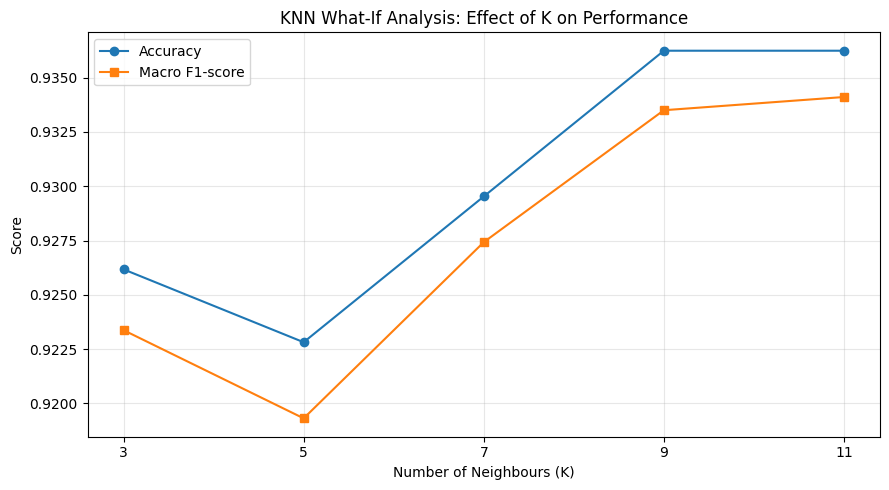

In [17]:
import matplotlib.pyplot as plt

# Plot KNN what-if experiment results
plt.figure(figsize=(9, 5))

plt.plot(
    knn_comparison["K Value"],
    knn_comparison["Accuracy"],
    marker="o",
    label="Accuracy"
)

plt.plot(
    knn_comparison["K Value"],
    knn_comparison["Macro F1-score"],
    marker="s",
    label="Macro F1-score"
)

plt.xlabel("Number of Neighbours (K)")
plt.ylabel("Score")
plt.title("KNN What-If Analysis: Effect of K on Performance")
plt.xticks(knn_comparison["K Value"])
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

DATASET OVERVIEW
Total documents: 1490
Total features: 3
Missing values:
 ArticleId    0
Text         0
Category     0
dtype: int64

CATEGORY DISTRIBUTION
Category
business         336
entertainment    273
politics         274
sport            346
tech             261
Name: count, dtype: int64

Number of categories: 5


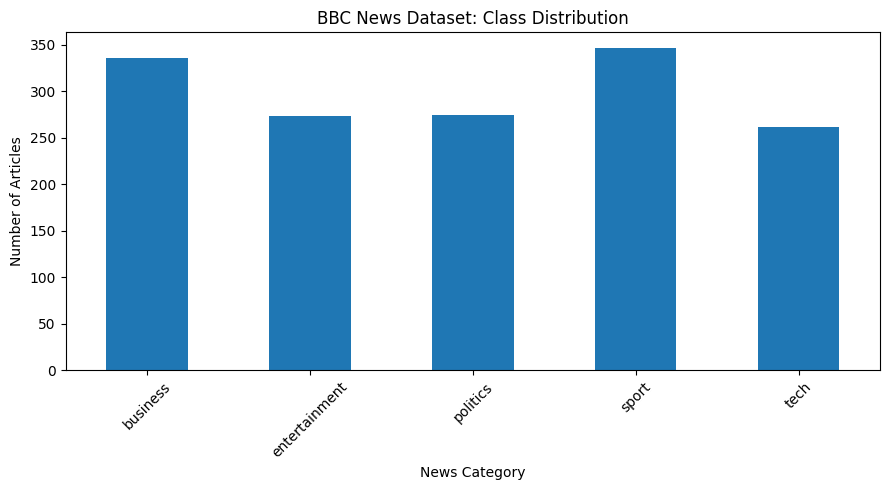

In [18]:
# PHASE 2: DATASET AND CLASS DISTRIBUTION ANALYSIS

import pandas as pd
import matplotlib.pyplot as plt

# Dataset overview
print("DATASET OVERVIEW")
print("=" * 40)

print("Total documents:", len(df))
print("Total features:", df.shape[1])
print("Missing values:\n", df.isnull().sum())

# Category distribution
category_counts = df["Category"].value_counts().sort_index()

print("\nCATEGORY DISTRIBUTION")
print("=" * 40)
print(category_counts)

print("\nNumber of categories:", df["Category"].nunique())

# Visualize class distribution
plt.figure(figsize=(9, 5))

category_counts.plot(kind="bar")

plt.title("BBC News Dataset: Class Distribution")
plt.xlabel("News Category")
plt.ylabel("Number of Articles")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Dataset Description and Class Distribution

The BBC News dataset was selected for the text classification task. It contains 1,490 news articles distributed across five categories: Business, Entertainment, Politics, Sport, and Tech. Each record contains an article identifier, the article text, and its corresponding category label.

The dataset was inspected for missing values, and no missing values were found in the ArticleId, Text, or Category columns. A class distribution analysis was performed using a bar chart to examine the number of articles belonging to each category.

The dataset contains some variation in class frequencies, with Sport having the largest number of articles and Tech having the smallest. However, the distribution is reasonably balanced, so no immediate class-balancing technique was considered necessary. Stratified train-test splitting was used to preserve the approximate class proportions during model evaluation.

In [19]:
# PHASE 3: VERIFY TEXT PREPROCESSING AND TF-IDF

print("=" * 50)
print("TEXT PREPROCESSING AND TF-IDF VERIFICATION")
print("=" * 50)

# Check dataset dimensions
print("\nDataset shape:", df.shape)

# Check the required columns
print("\nDataset columns:", df.columns.tolist())

# Check for missing text and labels
print("\nMissing text values:", df["Text"].isnull().sum())
print("Missing category values:", df["Category"].isnull().sum())

# Inspect a sample article
print("\nSample article:")
print(df["Text"].iloc[0][:500])

# Verify the TF-IDF matrices
print("\nTraining TF-IDF shape:", X_train.shape)
print("Testing TF-IDF shape:", X_test.shape)

# Verify vocabulary size
print("TF-IDF vocabulary size:", len(tfidf.vocabulary_))

# Verify labels
print("Training labels:", len(y_train))
print("Testing labels:", len(y_test))

print("\nVerification completed.")

TEXT PREPROCESSING AND TF-IDF VERIFICATION

Dataset shape: (1490, 3)

Dataset columns: ['ArticleId', 'Text', 'Category']

Missing text values: 0
Missing category values: 0

Sample article:
worldcom ex-boss launches defence lawyers defending former worldcom chief bernie ebbers against a battery of fraud charges have called a company whistleblower as their first witness.  cynthia cooper  worldcom s ex-head of internal accounting  alerted directors to irregular accounting practices at the us telecoms giant in 2002. her warnings led to the collapse of the firm following the discovery of an $11bn (£5.7bn) accounting fraud. mr ebbers has pleaded not guilty to charges of fraud and conspi

Training TF-IDF shape: (1192, 5000)
Testing TF-IDF shape: (298, 5000)
TF-IDF vocabulary size: 5000
Training labels: 1192
Testing labels: 298

Verification completed.


In [20]:
from IPython.display import display as ipy_display
import pandas as pd

# Reference the correct variable 'results_df'
# Convert to DataFrame if it's a list (though results_df is already a DataFrame)
evaluation_df = results_df.copy() if 'results_df' in globals() else pd.DataFrame()

if not evaluation_df.empty:
    # Sort models by Macro F1-score
    evaluation_df = evaluation_df.sort_values(
        by="F1-score (Macro)",
        ascending=False
    ).reset_index(drop=True)

    # Display final comparison
    print("FINAL MODEL COMPARISON")
    ipy_display(evaluation_df)

    # Identify the best-performing model
    best_model = evaluation_df.iloc[0]

    print("\nBEST-PERFORMING MODEL:")
    print("Model:", best_model["Model"])
    print("Accuracy:", round(best_model["Accuracy"] * 100, 2), "%")
    print("Macro Precision:", round(best_model["Precision (Macro)"] * 100, 2), "%")
    print("Macro Recall:", round(best_model["Recall (Macro)"] * 100, 2), "%")
    print("Macro F1-score:", round(best_model["F1-score (Macro)"] * 100, 2), "%")
else:
    print("Error: 'results_df' is not defined. Please run the Model Training cell (Phase 4) first.")

FINAL MODEL COMPARISON


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro),Training Time (s),Testing Time (s)
0,Naive Bayes,0.976510,0.976077,0.975428,0.975726,0.020306,0.000868
1,SVM,0.976510,0.976437,0.975009,0.975482,0.163977,0.005245
2,KNN,0.922819,0.919471,0.919454,0.919314,0.009304,0.111080
3,Decision Tree,0.828859,0.827217,0.822143,0.823992,1.884040,0.003330



BEST-PERFORMING MODEL:
Model: Naive Bayes
Accuracy: 97.65 %
Macro Precision: 97.61 %
Macro Recall: 97.54 %
Macro F1-score: 97.57 %


## Comparative Analysis of Four Classification Algorithms

Four machine learning classifiers—Decision Tree, K-Nearest Neighbours (KNN), Support Vector Machine (SVM), and Naive Bayes—were evaluated using the BBC News dataset. The dataset contains five categories: business, entertainment, politics, sport, and technology. All four classifiers were evaluated using the same TF-IDF feature representation and train-test split.

### 1. Performance Comparison

Naive Bayes achieved the highest Macro F1-score of 97.57%, with an accuracy of 97.65%. SVM achieved the same accuracy of 97.65% and a slightly lower Macro F1-score of 97.55%. Both models demonstrated excellent classification performance.

KNN achieved an accuracy of 92.28% and a Macro F1-score of 91.93%. Although its performance was lower than that of Naive Bayes and SVM, it classified most news articles correctly.

Decision Tree achieved an accuracy of 82.89% and a Macro F1-score of 82.40%, making it the lowest-performing classifier among the four models.

### 2. Analysis of Algorithm Behaviour

**Naive Bayes:** This algorithm performed exceptionally well because it is well suited to high-dimensional text classification. It estimates class probabilities from word features and makes predictions efficiently.

**Support Vector Machine (SVM):** SVM achieved excellent performance by learning decision boundaries that separate the news categories. Its results were almost identical to those of Naive Bayes.

**K-Nearest Neighbours (KNN):** KNN classifies documents based on the similarity of their feature vectors to neighbouring documents. Its performance depends on the choice of K and the distance metric.

**Decision Tree:** Decision Tree achieved lower performance than the other classifiers. A single tree may struggle to generalise effectively from sparse, high-dimensional TF-IDF features.

### 3. Final Recommendation

Naive Bayes is the recommended classifier for this experiment because it achieved the highest Macro F1-score of 97.57%. However, SVM is a very close competitor, with a Macro F1-score of 97.55% and the same accuracy of 97.65%.

The difference between the two models is small. Therefore, the final choice should also consider computational cost, prediction speed, and the requirements of the intended application.

Overall, both Naive Bayes and SVM are strong candidates for BBC News classification, while KNN and Decision Tree provide useful comparison baselines.

# Final Conclusion

In this project, four machine learning algorithms—Decision Tree, K-Nearest Neighbours (KNN), Support Vector Machine (SVM), and Naive Bayes—were implemented to classify BBC News articles into five categories: business, entertainment, politics, sport, and technology. The dataset contained 1,490 articles, which were preprocessed and converted into numerical features using TF-IDF vectorization. The dataset was divided into training and testing sets to evaluate the classifiers under the same experimental conditions.

The experimental results showed that Naive Bayes and SVM achieved the best overall performance. Naive Bayes obtained an accuracy of 97.65% and a Macro F1-score of 97.57%, while SVM achieved an accuracy of 97.65% and a Macro F1-score of 97.55%. KNN achieved an accuracy of 92.28%, whereas Decision Tree achieved 82.89%.

A what-if experiment was also conducted by varying the number of neighbours in KNN from 3 to 11. The results showed that K = 9 and K = 11 achieved the highest accuracy of 93.62%. K = 11 produced the highest Macro F1-score of 93.41%. This experiment demonstrated that the choice of K influences classification performance.

Based on the experimental results, Naive Bayes is the best-performing classifier according to Macro F1-score. However, its performance is very close to that of SVM. The final choice between these two algorithms may depend on computational requirements and the intended application.

Overall, this project demonstrates that TF-IDF combined with suitable machine learning algorithms can effectively classify news articles. It also highlights the importance of fair evaluation, confusion matrix analysis, comparative visualisation, and parameter tuning when selecting a text classification model.